In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from pathlib import Path 

print("EDA enviornment initialized successfully.")

EDA enviornment initialized successfully.


In [3]:
BASE_DIR = Path.cwd().parent
DATA_DIR = BASE_DIR /"data"/"raw"

print("Project directory:", BASE_DIR)
print("Data directory:", DATA_DIR)



Project directory: /Users/sumit/developer/oa/rag
Data directory: /Users/sumit/developer/oa/rag/data/raw


In [4]:
sales = pd.read_csv(
    DATA_DIR/ "sales_train_evaluation.csv"
)

calendar = pd.read_csv(
    DATA_DIR/ "calendar.csv"
)

prices = pd.read_csv(
    DATA_DIR / "sell_prices.csv"
)
print("All datasets are loaded")



All datasets are loaded


In [5]:
print("Sales shape:", sales.shape)
print("Calendar shape :", calendar.shape)
print("Prices shape:", prices.shape)



Sales shape: (30490, 1947)
Calendar shape : (1969, 14)
Prices shape: (6841121, 4)


In [6]:
sales.head()


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,2,0,0,0,2,3,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,1,0,4,0,1,3,0,2,6
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,2,1,0,0,2,1,0


In [7]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 30490 entries, 0 to 30489
Columns: 1947 entries, id to d_1941
dtypes: int64(1941), str(6)
memory usage: 454.7 MB


In [8]:
sales.isnull().sum().sort_values(ascending=False)


id        0
d_1273    0
d_1301    0
d_1300    0
d_1299    0
         ..
d_639     0
d_638     0
d_637     0
d_636     0
d_1941    0
Length: 1947, dtype: int64

In [9]:
print("number of prod :", sales["item_id"].nunique())
print("number of departments :", sales["dept_id"].nunique())
print("number of categories :", sales["cat_id"].nunique())
print("number of stores :", sales["store_id"].nunique())
print("number of states :", sales["state_id"].nunique())

number of prod : 3049
number of departments : 7
number of categories : 3
number of stores : 10
number of states : 3


In [10]:
print("\nStores:")
print(sales["store_id"].unique())
print("\nStates:")
print(sales["state_id"].unique())
print("\nCategories:")
print(sales["cat_id"].unique())


Stores:
<ArrowStringArray>
['CA_1', 'CA_2', 'CA_3', 'CA_4', 'TX_1', 'TX_2', 'TX_3', 'WI_1', 'WI_2',
 'WI_3']
Length: 10, dtype: str

States:
<ArrowStringArray>
['CA', 'TX', 'WI']
Length: 3, dtype: str

Categories:
<ArrowStringArray>
['HOBBIES', 'HOUSEHOLD', 'FOODS']
Length: 3, dtype: str


In [12]:
day_columns = [
    column for column in sales.columns
    if column.startswith("d_")
]

print("Number of daily columns:", len(day_columns))
print("First 10 : ", day_columns[:10])
print("Last 10 : ", day_columns[-10:])

Number of daily columns: 1941
First 10 :  ['d_1', 'd_2', 'd_3', 'd_4', 'd_5', 'd_6', 'd_7', 'd_8', 'd_9', 'd_10']
Last 10 :  ['d_1932', 'd_1933', 'd_1934', 'd_1935', 'd_1936', 'd_1937', 'd_1938', 'd_1939', 'd_1940', 'd_1941']


In [13]:
total_units_sold = sales[day_columns].sum().sum()

print("Total historical units sold:", total_units_sold)

Total historical units sold: 66927173


In [14]:
category_sales= (sales.groupby("cat_id")[day_columns]
    .sum()
    .sum(axis=1)
    .sort_values(ascending=False)
)
category_sales

cat_id
FOODS        45922427
HOUSEHOLD    14764090
HOBBIES       6240656
dtype: int64

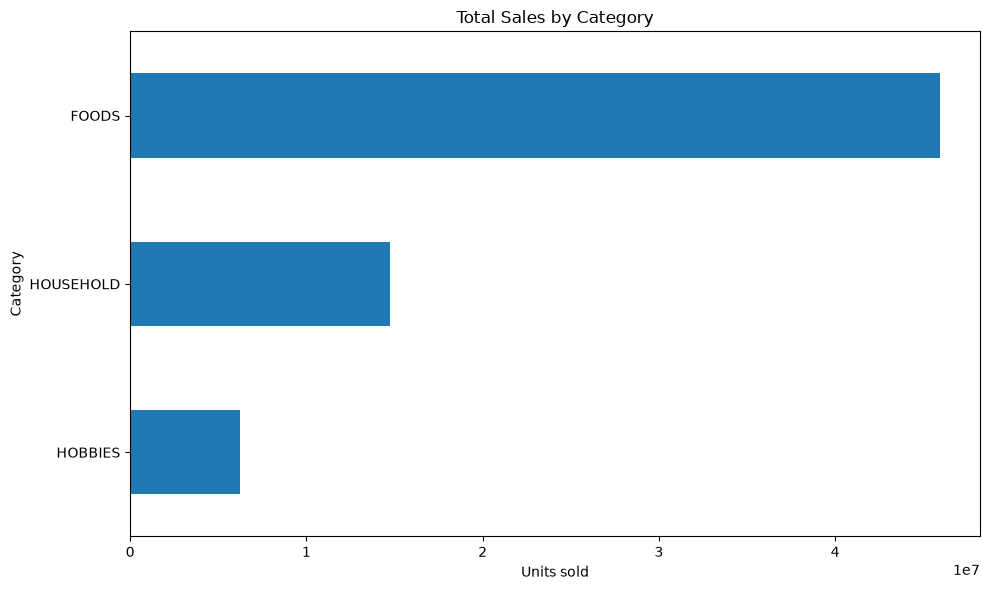

In [16]:
plt.figure(figsize=(10, 6))
category_sales.sort_values().plot(kind="barh")
plt.title("Total Sales by Category")
plt.xlabel("Units sold")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [17]:
store_sales=(
    sales.groupby("store_id")[day_columns]
    .sum()
    .sum(axis=1)
    .sort_values(ascending=False)
)
store_sales

store_id
CA_3    11363540
CA_1     7832248
TX_2     7329642
WI_2     6697988
WI_3     6542557
TX_3     6205940
CA_2     5818395
TX_1     5692823
WI_1     5261506
CA_4     4182534
dtype: int64

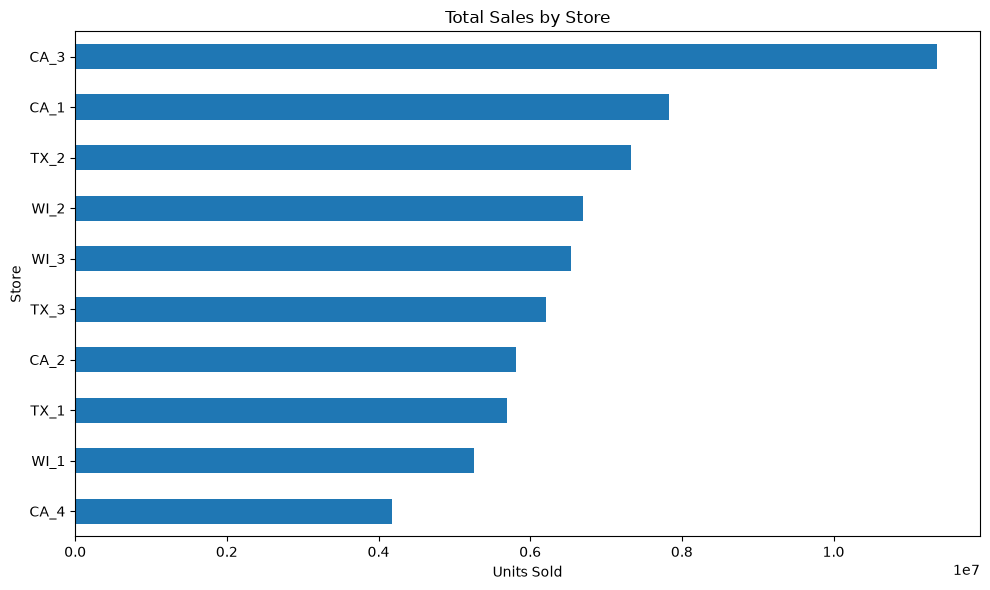

In [19]:
plt.figure(figsize=(10, 6))
store_sales.sort_values().plot(kind="barh")
plt.title("Total Sales by Store")
plt.xlabel("Units Sold")
plt.ylabel("Store")

plt.tight_layout()
plt.show()


In [20]:
product_sales=(
    sales.groupby("item_id")[day_columns]
    .sum()
    .sum(axis=1)
    .sort_values(ascending=False)
)
top_10_products= product_sales.head(10)

top_10_products

item_id
FOODS_3_090    1017916
FOODS_3_586     932236
FOODS_3_252     573723
FOODS_3_555     497881
FOODS_3_587     402159
FOODS_3_714     402111
FOODS_3_694     395937
FOODS_3_226     368369
FOODS_3_202     300529
FOODS_3_120     290132
dtype: int64

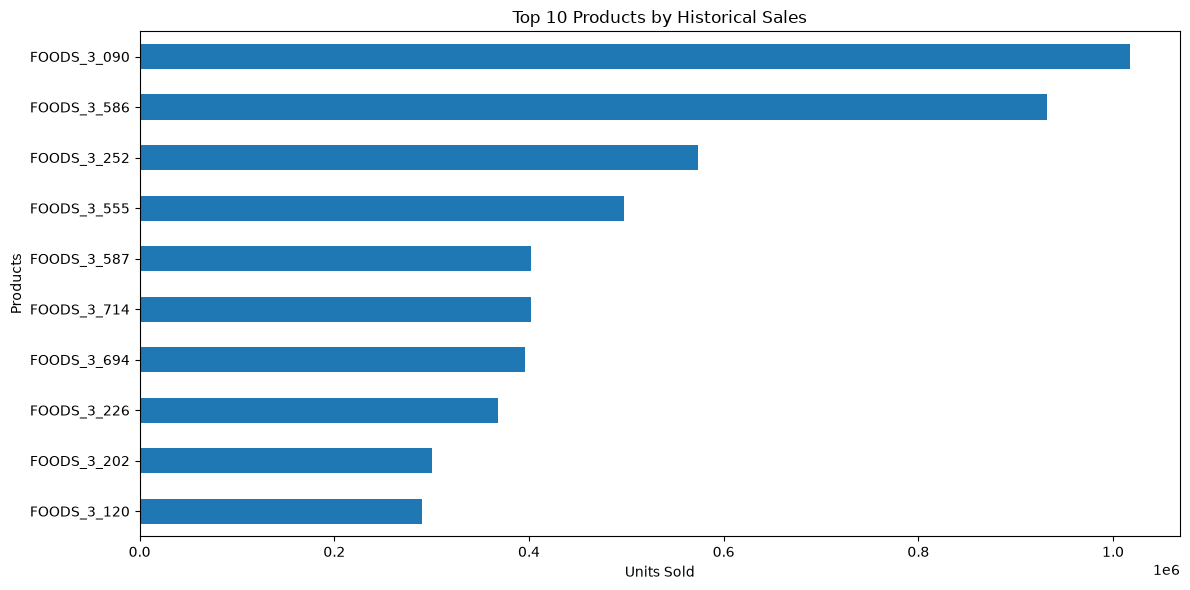

In [22]:
plt.figure(figsize=(12, 6))
top_10_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Historical Sales")
plt.xlabel("Units Sold")
plt.ylabel("Products")

plt.tight_layout()
plt.show()

In [23]:
calendar.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [24]:
calendar.info()

<class 'pandas.DataFrame'>
RangeIndex: 1969 entries, 0 to 1968
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   date          1969 non-null   str  
 1   wm_yr_wk      1969 non-null   int64
 2   weekday       1969 non-null   str  
 3   wday          1969 non-null   int64
 4   month         1969 non-null   int64
 5   year          1969 non-null   int64
 6   d             1969 non-null   str  
 7   event_name_1  162 non-null    str  
 8   event_type_1  162 non-null    str  
 9   event_name_2  5 non-null      str  
 10  event_type_2  5 non-null      str  
 11  snap_CA       1969 non-null   int64
 12  snap_TX       1969 non-null   int64
 13  snap_WI       1969 non-null   int64
dtypes: int64(7), str(7)
memory usage: 263.1 KB


In [ ]:
calendar["date"]= pd.to_datetime(calendar["date"])

In [26]:
print("State date:", calendar["date"].min())
print("End date:", calendar["date"].max())

State date: 2011-01-29 00:00:00
End date: 2016-06-19 00:00:00


In [27]:
calendar[["date", "weekday", "wday", "month", "year", "d"]].head(10)

,date,weekday,wday,month,year,d
0,2011-01-29,Saturday,1,1,2011,d_1
1,2011-01-30,Sunday,2,1,2011,d_2
2,2011-01-31,Monday,3,1,2011,d_3
3,2011-02-01,Tuesday,4,2,2011,d_4
4,2011-02-02,Wednesday,5,2,2011,d_5
5,2011-02-03,Thursday,6,2,2011,d_6
6,2011-02-04,Friday,7,2,2011,d_7
7,2011-02-05,Saturday,1,2,2011,d_8
8,2011-02-06,Sunday,2,2,2011,d_9
9,2011-02-07,Monday,3,2,2011,d_10


In [28]:
calendar["weekday"].value_counts()

weekday
Saturday     282
Sunday       282
Monday       281
Tuesday      281
Wednesday    281
Thursday     281
Friday       281
Name: count, dtype: int64

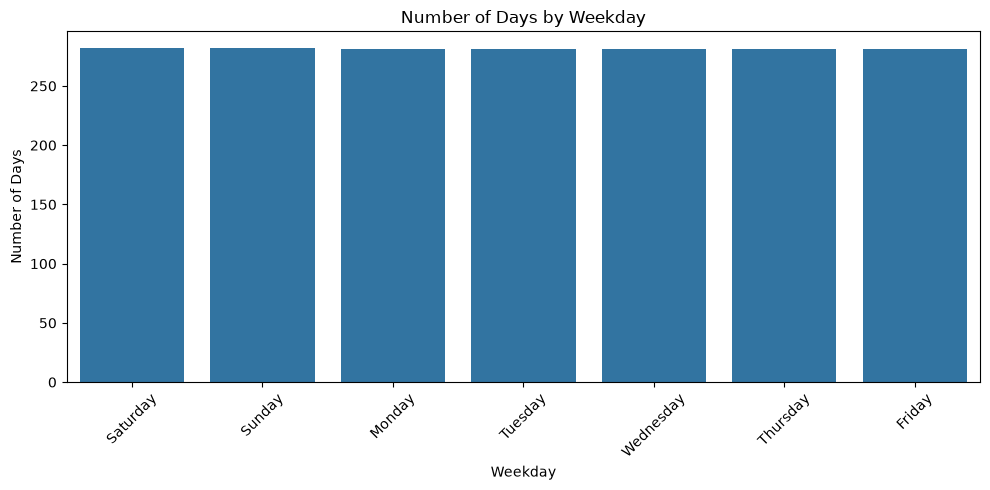

In [29]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data= calendar,
    x= "weekday",
    order= calendar["weekday"].value_counts().index
)

plt.title("Number of Days by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Number of Days")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
events= calendar[
    ["date", "event_name_1", "event_type_1"]
].dropna(subset=["event_name_1"])

events.head(20)

,date,event_name_1,event_type_1
8,2011-02-06,SuperBowl,Sporting
16,2011-02-14,ValentinesDay,Cultural
23,2011-02-21,PresidentsDay,National
39,2011-03-09,LentStart,Religious
46,2011-03-16,LentWeek2,Religious
47,2011-03-17,StPatricksDay,Cultural
50,2011-03-20,Purim End,Religious
85,2011-04-24,OrthodoxEaster,Religious
87,2011-04-26,Pesach End,Religious
96,2011-05-05,Cinco De Mayo,Cultural


In [32]:
events= calendar[
    ["date", "event_name_1", "event_name_1"]
].dropna(subset=["event_name_1"])

events.head(20)

,date,event_name_1,event_name_1
8,2011-02-06,SuperBowl,SuperBowl
16,2011-02-14,ValentinesDay,ValentinesDay
23,2011-02-21,PresidentsDay,PresidentsDay
39,2011-03-09,LentStart,LentStart
46,2011-03-16,LentWeek2,LentWeek2
47,2011-03-17,StPatricksDay,StPatricksDay
50,2011-03-20,Purim End,Purim End
85,2011-04-24,OrthodoxEaster,OrthodoxEaster
87,2011-04-26,Pesach End,Pesach End
96,2011-05-05,Cinco De Mayo,Cinco De Mayo


In [33]:
print("Number of event days:", len(events))

Number of event days: 162


In [34]:
prices.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [35]:
prices.info()

<class 'pandas.DataFrame'>
RangeIndex: 6841121 entries, 0 to 6841120
Data columns (total 4 columns):
 #   Column      Dtype  
---  ------      -----  
 0   store_id    str    
 1   item_id     str    
 2   wm_yr_wk    int64  
 3   sell_price  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 318.1 MB


In [36]:
prices.describe()

,wm_yr_wk,sell_price
count,6.841121e+06,6.841121e+06
mean,1.138294e+04,4.410952e+00
std,1.486100e+02,3.408814e+00
min,1.110100e+04,1.000000e-02
25%,1.124700e+04,2.180000e+00
50%,1.141100e+04,3.470000e+00
75%,1.151700e+04,5.840000e+00
max,1.162100e+04,1.073200e+02


In [37]:
prices["sell_price"].describe()

count    6.841121e+06
mean     4.410952e+00
std      3.408814e+00
min      1.000000e-02
25%      2.180000e+00
50%      3.470000e+00
75%      5.840000e+00
max      1.073200e+02
Name: sell_price, dtype: float64

In [38]:
print("Unique products with prices:", prices["item_id"].nunique())
print("Unique stores with prices:", prices["store_id"].nunique())

Unique products with prices: 3049
Unique stores with prices: 10


In [39]:
# from src.load_database import daily_demand
day_columns=[
    column for column in sales.columns
    if column.startswith("d_")
]

daily_demand= sales[day_columns].sum(axis=0)

daily_demand= daily_demand.reset_index()

daily_demand.columns= ["d", "units_sold"]

print("Daily demand dataset created.")
print("Shape:", daily_demand.shape)

daily_demand.head()

Daily demand dataset created.
Shape: (1941, 2)


,d,units_sold
0,d_1,32631
1,d_2,31749
2,d_3,23783
3,d_4,25412
4,d_5,19146


In [40]:
daily_demand= daily_demand.merge(
    calendar[["d", "date", "wm_yr_wk", "weekday", "wday", "month", "year"]],
    on="d",
    how="left"
)

print("Date mapping completed.")
print("Shape:", daily_demand.shape)
daily_demand.head()

Date mapping completed.
Shape: (1941, 8)


,d,units_sold,date,wm_yr_wk,weekday,wday,month,year
0,d_1,32631,2011-01-29,11101,Saturday,1,1,2011
1,d_2,31749,2011-01-30,11101,Sunday,2,1,2011
2,d_3,23783,2011-01-31,11101,Monday,3,1,2011
3,d_4,25412,2011-02-01,11101,Tuesday,4,2,2011
4,d_5,19146,2011-02-02,11101,Wednesday,5,2,2011


In [41]:
print("Start date:", daily_demand["date"].min())
print("End date:", daily_demand["date"].max())

Start date: 2011-01-29 00:00:00
End date: 2016-05-22 00:00:00


In [42]:
print(daily_demand.tail())

           d  units_sold       date  wm_yr_wk    weekday  wday  month  year
1936  d_1937       37096 2016-05-18     11616  Wednesday     5      5  2016
1937  d_1938       36963 2016-05-19     11616   Thursday     6      5  2016
1938  d_1939       42552 2016-05-20     11616     Friday     7      5  2016
1939  d_1940       51518 2016-05-21     11617   Saturday     1      5  2016
1940  d_1941       54338 2016-05-22     11617     Sunday     2      5  2016


In [43]:
print("Missing dates:", daily_demand["date"].isna().sum())
print("Missing demand:", daily_demand["units_sold"].isna().sum())


Missing dates: 0
Missing demand: 0


In [47]:
daily_demand= daily_demand.sort_values("date").reset_index(drop=True)
print(daily_demand.head())
print(daily_demand.tail())

     d  units_sold       date  wm_yr_wk    weekday  wday  month  year
0  d_1       32631 2011-01-29     11101   Saturday     1      1  2011
1  d_2       31749 2011-01-30     11101     Sunday     2      1  2011
2  d_3       23783 2011-01-31     11101     Monday     3      1  2011
3  d_4       25412 2011-02-01     11101    Tuesday     4      2  2011
4  d_5       19146 2011-02-02     11101  Wednesday     5      2  2011
           d  units_sold       date  wm_yr_wk    weekday  wday  month  year
1936  d_1937       37096 2016-05-18     11616  Wednesday     5      5  2016
1937  d_1938       36963 2016-05-19     11616   Thursday     6      5  2016
1938  d_1939       42552 2016-05-20     11616     Friday     7      5  2016
1939  d_1940       51518 2016-05-21     11617   Saturday     1      5  2016
1940  d_1941       54338 2016-05-22     11617     Sunday     2      5  2016


In [49]:
processed_path = DATA_DIR.parent / "processed" / "daily_demand.csv"

daily_demand.to_csv(processed_path, index=False)

print("Processed dataset saved successfully.")
print(processed_path)

Processed dataset saved successfully.
/Users/sumit/developer/oa/rag/data/processed/daily_demand.csv


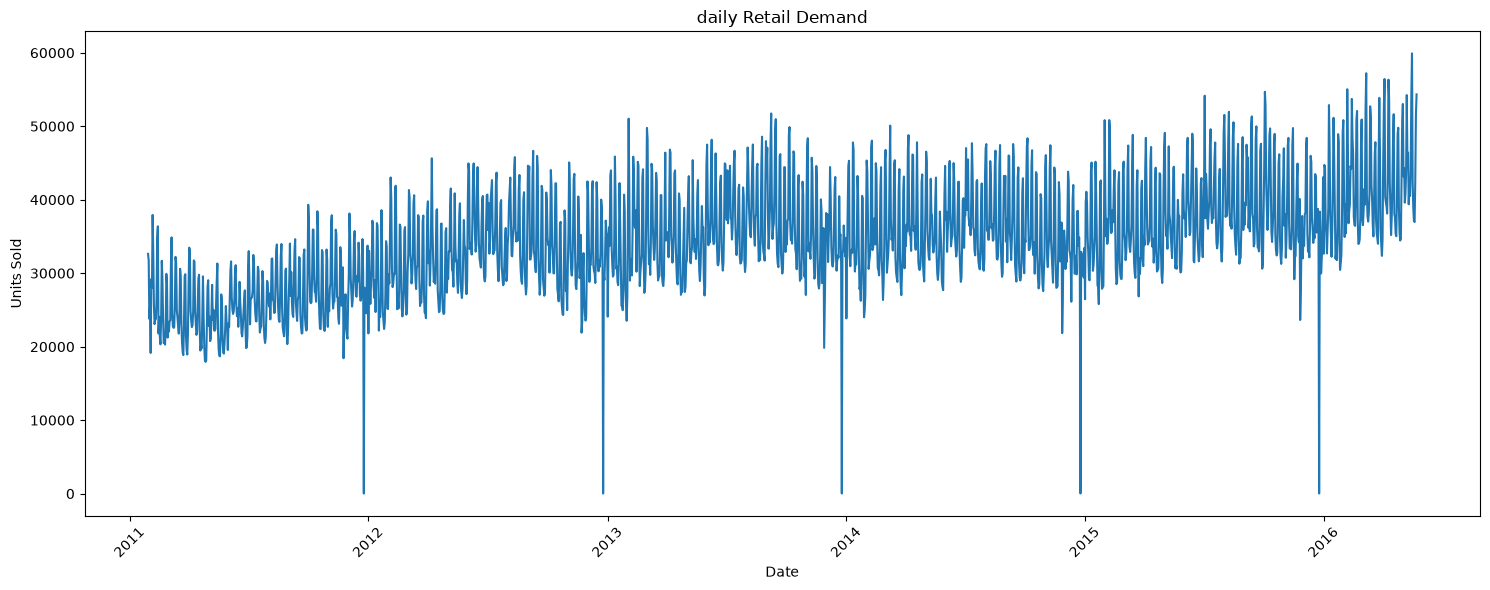

In [50]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_demand["date"],
    daily_demand["units_sold"]
)

plt.title("daily Retail Demand")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [51]:
print("Average daily demand:",
      daily_demand["units_sold"].mean())

print("Minimum daily demand:",
      daily_demand["units_sold"].min())

print("Maximum daily demand:",
      daily_demand["units_sold"].max())

print("Median daily demand:",
      daily_demand["units_sold"].median())

print("Standard deviation:",
      daily_demand["units_sold"].std())

Average daily demand: 34480.76919113859
Minimum daily demand: 11
Maximum daily demand: 59921
Median daily demand: 33830.0
Standard deviation: 7425.906822426444


In [52]:
print("Average daily demand:",
      daily_demand["units_sold"].mean())

print("Minimum daily demand:",
      daily_demand["units_sold"].min())

print("Maximum daily demand:",
      daily_demand["units_sold"].max())

print("Median daily demand:",
      daily_demand["units_sold"].median())

print("Standard deviation:",
      daily_demand["units_sold"].std())

Average daily demand: 34480.76919113859
Minimum daily demand: 11
Maximum daily demand: 59921
Median daily demand: 33830.0
Standard deviation: 7425.906822426444


In [53]:
monthly_demand= (
    daily_demand.
    set_index("date")
    .resample("ME")["units_sold"]
    .sum()
    .reset_index()
)

print(monthly_demand.head())
print("Monthly records:", len(monthly_demand))

        date  units_sold
0 2011-01-31       88163
1 2011-02-28      726375
2 2011-03-31      763567
3 2011-04-30      737713
4 2011-05-31      719562
Monthly records: 65


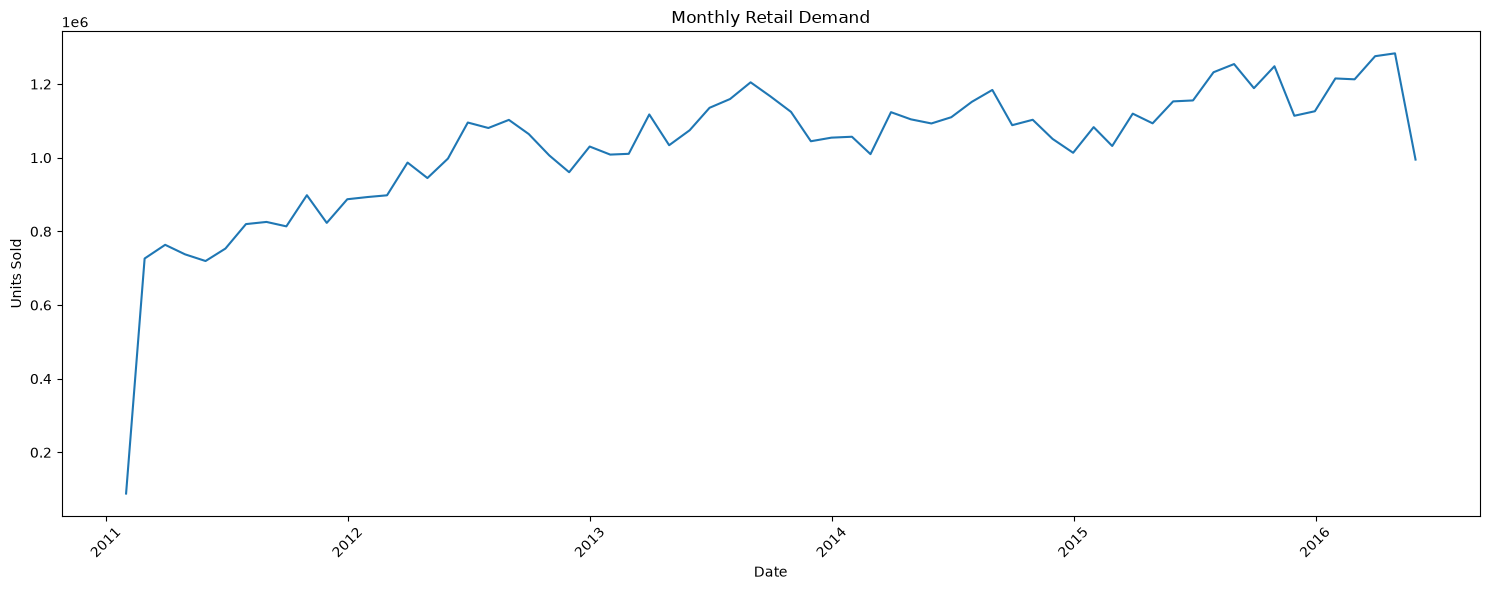

In [54]:
plt.figure(figsize=(15, 6))

plt.plot(
    monthly_demand["date"],
    monthly_demand["units_sold"]
)

plt.title("Monthly Retail Demand")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


In [55]:
weekday_demand=(
    daily_demand
    .groupby("weekday")["units_sold"]
    .mean()
)

print(weekday_demand)



weekday
Friday       34357.472924
Monday       32994.931408
Saturday     41706.269784
Sunday       41304.050360
Thursday     30321.039711
Tuesday      30500.483755
Wednesday    30130.418773
Name: units_sold, dtype: float64


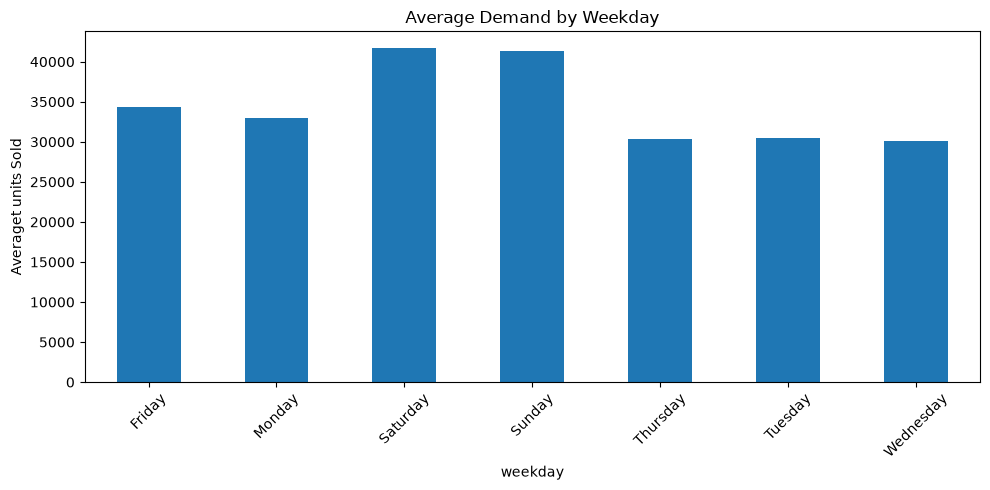

In [56]:

plt.figure(figsize=(10, 5))
weekday_demand.plot(kind="bar")
plt.title("Average Demand by Weekday")
plt.xlabel("weekday")
plt.ylabel("Averaget units Sold")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [57]:
monthly_average=(
    daily_demand
    .groupby("month")["units_sold"]
    .mean()
)

print(monthly_average)

month
1     33832.348101
2     34644.641176
3     34339.838710
4     34432.183333
5     34085.192090
6     35001.413333
7     35122.419355
8     35946.645161
9     35479.260000
10    34713.477419
11    33290.826667
12    32980.464516
Name: units_sold, dtype: float64


In [58]:
monthly_average = (
    daily_demand
    .groupby("month")["units_sold"]
    .mean()
)

print(monthly_average)

month
1     33832.348101
2     34644.641176
3     34339.838710
4     34432.183333
5     34085.192090
6     35001.413333
7     35122.419355
8     35946.645161
9     35479.260000
10    34713.477419
11    33290.826667
12    32980.464516
Name: units_sold, dtype: float64


In [59]:
daily_demand["rolling_7_day"]=(
    daily_demand["units_sold"]
    .rolling(window=7)
    .mean()
)

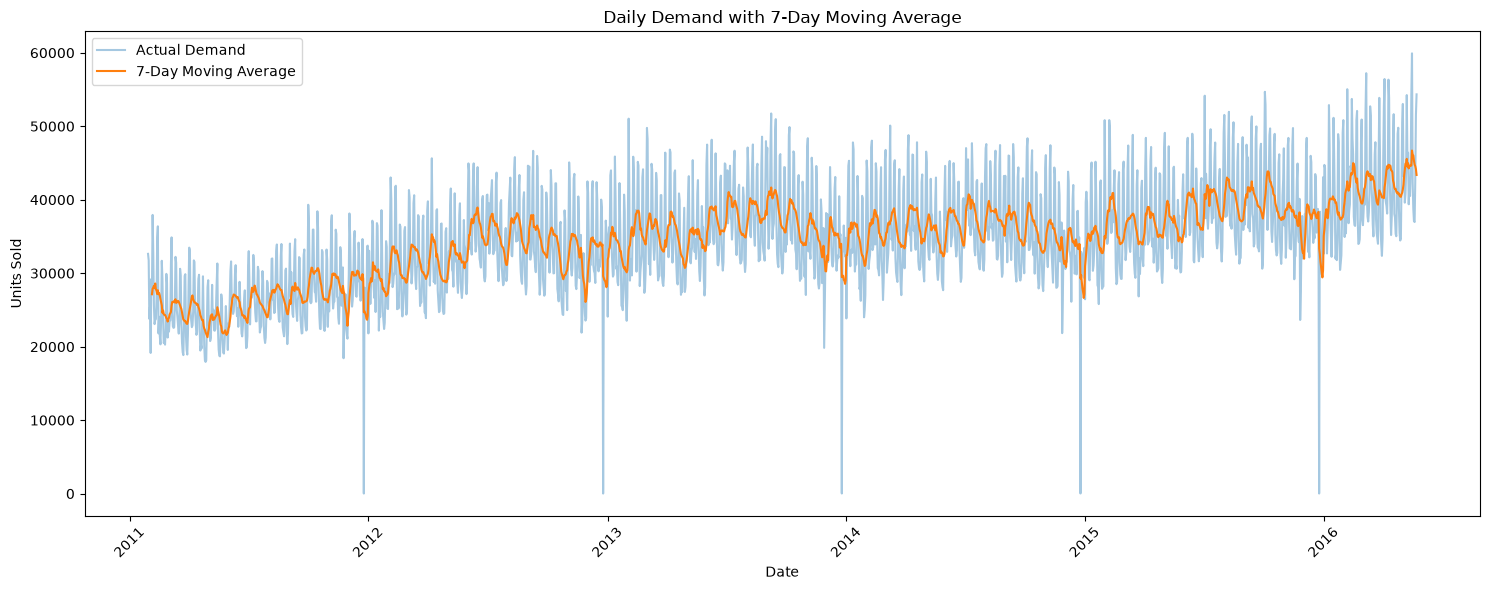

In [60]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_demand["date"],
    daily_demand["units_sold"],
    alpha=0.4,
    label="Actual Demand"
)

plt.plot(
    daily_demand["date"],
    daily_demand["rolling_7_day"],
    label="7-Day Moving Average"
)

plt.title("Daily Demand with 7-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [61]:
print(daily_demand.shape)
print(daily_demand.head())
print(daily_demand.tail())
print(daily_demand.isnull().sum())

(1941, 9)
     d  units_sold       date  wm_yr_wk    weekday  wday  month  year  \
0  d_1       32631 2011-01-29     11101   Saturday     1      1  2011   
1  d_2       31749 2011-01-30     11101     Sunday     2      1  2011   
2  d_3       23783 2011-01-31     11101     Monday     3      1  2011   
3  d_4       25412 2011-02-01     11101    Tuesday     4      2  2011   
4  d_5       19146 2011-02-02     11101  Wednesday     5      2  2011   

   rolling_7_day  
0            NaN  
1            NaN  
2            NaN  
3            NaN  
4            NaN  
           d  units_sold       date  wm_yr_wk    weekday  wday  month  year  \
1936  d_1937       37096 2016-05-18     11616  Wednesday     5      5  2016   
1937  d_1938       36963 2016-05-19     11616   Thursday     6      5  2016   
1938  d_1939       42552 2016-05-20     11616     Friday     7      5  2016   
1939  d_1940       51518 2016-05-21     11617   Saturday     1      5  2016   
1940  d_1941       54338 2016-05-22     11

In [62]:
daily_demand= daily_demand.sort_values("date").reset_index(drop=True)
print("data stored by date successfully.")

data stored by date successfully.


In [64]:
forecast_data = daily_demand[[
    "date",
    "units_sold"
]].copy()

print(forecast_data.head())
print(forecast_data.shape)

        date  units_sold
0 2011-01-29       32631
1 2011-01-30       31749
2 2011-01-31       23783
3 2011-02-01       25412
4 2011-02-02       19146
(1941, 2)


In [65]:
validation_days = 28

train = forecast_data.iloc[:-validation_days].copy()
validation = forecast_data.iloc[-validation_days:].copy()

print("Training data:")
print(train.shape)

print("\nValidation data:")
print(validation.shape)

print("\nTraining period:")
print(train["date"].min(), "to", train["date"].max())

print("\nValidation period:")
print(validation["date"].min(), "to", validation["date"].max())

Training data:
(1913, 2)

Validation data:
(28, 2)

Training period:
2011-01-29 00:00:00 to 2016-04-24 00:00:00

Validation period:
2016-04-25 00:00:00 to 2016-05-22 00:00:00


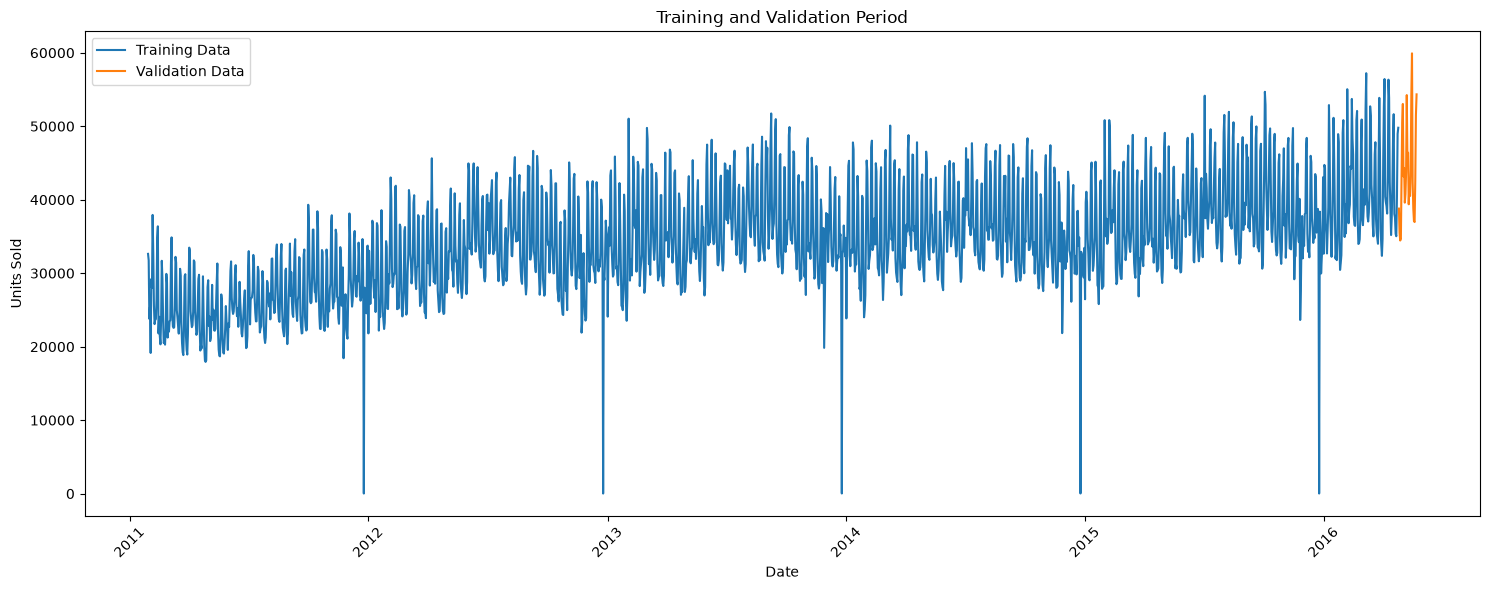

In [66]:
plt.figure(figsize=(15, 6))

plt.plot(
    train["date"],
    train["units_sold"],
    label="Training Data"
)

plt.plot(
    validation["date"],
    validation["units_sold"],
    label="Validation Data"
)

plt.title("Training and Validation Period")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


In [67]:
train_path = DATA_DIR.parent / "processed" / "train_daily_demand.csv"
validation_path = DATA_DIR.parent / "processed" / "validation_daily_demand.csv"

train.to_csv(train_path, index=False)
validation.to_csv(validation_path, index=False)

print("Training dataset saved:")
print(train_path)

print("\nValidation dataset saved:")
print(validation_path)

Training dataset saved:
/Users/sumit/developer/oa/rag/data/processed/train_daily_demand.csv

Validation dataset saved:
/Users/sumit/developer/oa/rag/data/processed/validation_daily_demand.csv
